# Wrapper Methods For Feature Selection

1) **Exhaustive Feature Selection Method**
2) **Forward Selection Method**
3) **Backward Elimination Method** and
4) **Recursive Feature Eliminination Method**

**Here, in this session, we will learn first three methods**

# 1) `Exhaustive Feature Selection Method`

We will learn in **`Iris Dataset`**

In [43]:
import pandas as pd
import numpy as np

# Pandas
pd.set_option('display.float_format', '{:.4f}'.format)

# NumPy
np.set_printoptions(suppress=True, precision=4)

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LogisticRegression, LinearRegression


In [2]:
df = pd.read_csv(r"00 Iris.csv")

df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1000,3.5000,1.4000,0.2000,Iris-setosa
1,2,4.9000,3.0000,1.4000,0.2000,Iris-setosa
2,3,4.7000,3.2000,1.3000,0.2000,Iris-setosa
3,4,4.6000,3.1000,1.5000,0.2000,Iris-setosa
4,5,5.0000,3.6000,1.4000,0.2000,Iris-setosa


In [3]:
x = df.iloc[:, 1:5]
y = df['Species']

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, shuffle = True, random_state = 1)

In [4]:
from mlxtend.feature_selection import ExhaustiveFeatureSelector as EFS

lr = LogisticRegression()
efs = EFS(
    estimator = lr,
    min_features = 1,
    max_features = 4,
    scoring = 'accuracy',
    cv = 5
)

model = efs.fit(x_train, y_train)

Features: 15/15

In [5]:
model.best_score_

np.float64(0.975)

In [6]:
model.best_feature_names_

('PetalLengthCm', 'PetalWidthCm')

In [7]:
model.subsets_

{0: {'feature_idx': (0,),
  'cv_scores': array([0.7083, 0.7917, 0.7083, 0.75  , 0.7083]),
  'avg_score': np.float64(0.7333333333333334),
  'feature_names': ('SepalLengthCm',)},
 1: {'feature_idx': (1,),
  'cv_scores': array([0.5833, 0.6667, 0.5   , 0.5   , 0.5   ]),
  'avg_score': np.float64(0.55),
  'feature_names': ('SepalWidthCm',)},
 2: {'feature_idx': (2,),
  'cv_scores': array([1.    , 0.9167, 0.9167, 1.    , 0.9167]),
  'avg_score': np.float64(0.95),
  'feature_names': ('PetalLengthCm',)},
 3: {'feature_idx': (3,),
  'cv_scores': array([0.9167, 0.9583, 1.    , 0.9583, 0.875 ]),
  'avg_score': np.float64(0.9416666666666668),
  'feature_names': ('PetalWidthCm',)},
 4: {'feature_idx': (0, 1),
  'cv_scores': array([0.75  , 0.875 , 0.7917, 0.8333, 0.7917]),
  'avg_score': np.float64(0.8083333333333333),
  'feature_names': ('SepalLengthCm', 'SepalWidthCm')},
 5: {'feature_idx': (0, 2),
  'cv_scores': array([1.    , 0.9167, 0.9583, 0.9583, 0.9167]),
  'avg_score': np.float64(0.95),
  '

In [8]:
pd.DataFrame(model.subsets_).T

,feature_idx,cv_scores,avg_score,feature_names
0,"(0,)","[0.7083333333333334, 0.7916666666666666, 0.708...",0.7333,"(SepalLengthCm,)"
1,"(1,)","[0.5833333333333334, 0.6666666666666666, 0.5, ...",0.5500,"(SepalWidthCm,)"
2,"(2,)","[1.0, 0.9166666666666666, 0.9166666666666666, ...",0.9500,"(PetalLengthCm,)"
3,"(3,)","[0.9166666666666666, 0.9583333333333334, 1.0, ...",0.9417,"(PetalWidthCm,)"
4,"(0, 1)","[0.75, 0.875, 0.7916666666666666, 0.8333333333...",0.8083,"(SepalLengthCm, SepalWidthCm)"
5,"(0, 2)","[1.0, 0.9166666666666666, 0.9583333333333334, ...",0.9500,"(SepalLengthCm, PetalLengthCm)"
6,"(0, 3)","[0.9583333333333334, 0.9583333333333334, 0.958...",0.9250,"(SepalLengthCm, PetalWidthCm)"
7,"(1, 2)","[1.0, 0.9166666666666666, 0.9166666666666666, ...",0.9417,"(SepalWidthCm, PetalLengthCm)"
8,"(1, 3)","[0.9166666666666666, 1.0, 0.9583333333333334, ...",0.9500,"(SepalWidthCm, PetalWidthCm)"
9,"(2, 3)","[1.0, 0.9583333333333334, 1.0, 0.9583333333333...",0.9750,"(PetalLengthCm, PetalWidthCm)"


In [9]:
model.get_metric_dict()

{0: {'feature_idx': (0,),
  'cv_scores': array([0.7083, 0.7917, 0.7083, 0.75  , 0.7083]),
  'avg_score': np.float64(0.7333333333333334),
  'feature_names': ('SepalLengthCm',),
  'ci_bound': np.float64(0.04284303059393855),
  'std_dev': np.float64(0.033333333333333305),
  'std_err': np.float64(0.016666666666666653)},
 1: {'feature_idx': (1,),
  'cv_scores': array([0.5833, 0.6667, 0.5   , 0.5   , 0.5   ]),
  'avg_score': np.float64(0.55),
  'feature_names': ('SepalWidthCm',),
  'ci_bound': np.float64(0.08568606118787715),
  'std_dev': np.float64(0.06666666666666667),
  'std_err': np.float64(0.033333333333333326)},
 2: {'feature_idx': (2,),
  'cv_scores': array([1.    , 0.9167, 0.9167, 1.    , 0.9167]),
  'avg_score': np.float64(0.95),
  'feature_names': ('PetalLengthCm',),
  'ci_bound': np.float64(0.052471781994799245),
  'std_dev': np.float64(0.04082482904638632),
  'std_err': np.float64(0.02041241452319316)},
 3: {'feature_idx': (3,),
  'cv_scores': array([0.9167, 0.9583, 1.    , 0.958

In [10]:
metric_df = pd.DataFrame(model.get_metric_dict()).T
metric_df

,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err
0,"(0,)","[0.7083333333333334, 0.7916666666666666, 0.708...",0.7333,"(SepalLengthCm,)",0.0428,0.0333,0.0167
1,"(1,)","[0.5833333333333334, 0.6666666666666666, 0.5, ...",0.5500,"(SepalWidthCm,)",0.0857,0.0667,0.0333
2,"(2,)","[1.0, 0.9166666666666666, 0.9166666666666666, ...",0.9500,"(PetalLengthCm,)",0.0525,0.0408,0.0204
3,"(3,)","[0.9166666666666666, 0.9583333333333334, 1.0, ...",0.9417,"(PetalWidthCm,)",0.0546,0.0425,0.0212
4,"(0, 1)","[0.75, 0.875, 0.7916666666666666, 0.8333333333...",0.8083,"(SepalLengthCm, SepalWidthCm)",0.0546,0.0425,0.0212
5,"(0, 2)","[1.0, 0.9166666666666666, 0.9583333333333334, ...",0.9500,"(SepalLengthCm, PetalLengthCm)",0.0401,0.0312,0.0156
6,"(0, 3)","[0.9583333333333334, 0.9583333333333334, 0.958...",0.9250,"(SepalLengthCm, PetalWidthCm)",0.0525,0.0408,0.0204
7,"(1, 2)","[1.0, 0.9166666666666666, 0.9166666666666666, ...",0.9417,"(SepalWidthCm, PetalLengthCm)",0.0428,0.0333,0.0167
8,"(1, 3)","[0.9166666666666666, 1.0, 0.9583333333333334, ...",0.9500,"(SepalWidthCm, PetalWidthCm)",0.0401,0.0312,0.0156
9,"(2, 3)","[1.0, 0.9583333333333334, 1.0, 0.9583333333333...",0.9750,"(PetalLengthCm, PetalWidthCm)",0.0262,0.0204,0.0102


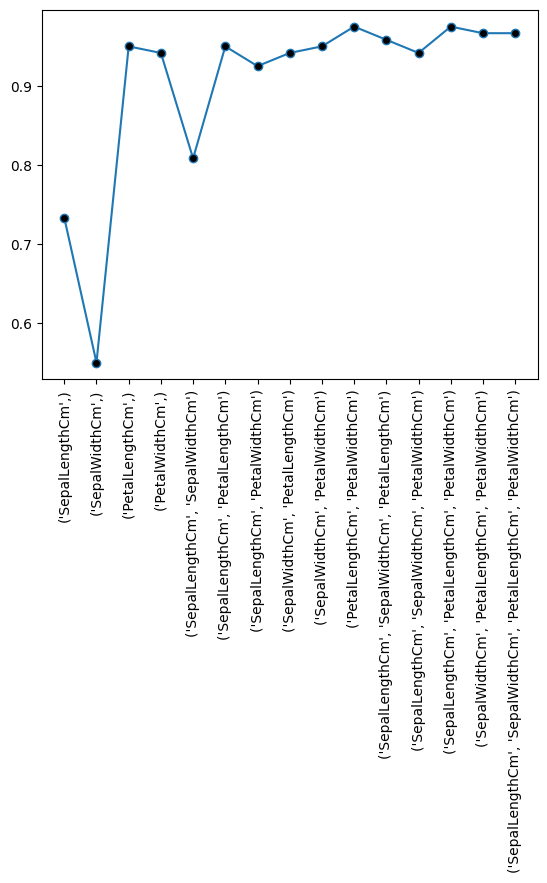

In [11]:
import matplotlib.pyplot as plt

plt.plot([str(k) for k in metric_df['feature_names']],metric_df['avg_score'], marker = 'o', markerfacecolor = 'black')
plt.xticks(rotation=90)
plt.show()

In [12]:
[str(k) for k in metric_df['feature_names']]

["('SepalLengthCm',)",
 "('SepalWidthCm',)",
 "('PetalLengthCm',)",
 "('PetalWidthCm',)",
 "('SepalLengthCm', 'SepalWidthCm')",
 "('SepalLengthCm', 'PetalLengthCm')",
 "('SepalLengthCm', 'PetalWidthCm')",
 "('SepalWidthCm', 'PetalLengthCm')",
 "('SepalWidthCm', 'PetalWidthCm')",
 "('PetalLengthCm', 'PetalWidthCm')",
 "('SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm')",
 "('SepalLengthCm', 'SepalWidthCm', 'PetalWidthCm')",
 "('SepalLengthCm', 'PetalLengthCm', 'PetalWidthCm')",
 "('SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm')",
 "('SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm')"]

In [ ]:
print(model.best_score_)
print(model.best_feature_names_)

0.975
('PetalLengthCm', 'PetalWidthCm')


# Remember
- While selecting the best subset, we don't only analyze avg_accuracy scores.
- Along with avg_accuracy_scores, we also analyze std_deviation
- Here in the last table, std_dev column represents the std_dev of all 5 trained models (CV = 5)
- If std is high, it means model is not getting stable and vice versa.
- **Model A**
    - Accuracy:
    - 0.95, 0.95, 0.95, 0.95, 0.95
    - Mean = 0.95
    - Std  = 0

- **Model B**
    - Accuracy:
    - 1.00, 1.00, 0.90, 1.00, 1.00
    - Mean = 0.98
    - Std  = higher

- Model B has better average accuracy, but its performance is less consistent.
- **So model A is better than model B**

# Regression Example

In [ ]:
df = pd.read_csv('https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv')
df.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.0063,18.0000,2.3100,0,0.5380,6.5750,65.2000,4.0900,1,296,15.3000,396.9000,4.9800,24.0000
1,0.0273,0.0000,7.0700,0,0.4690,6.4210,78.9000,4.9671,2,242,17.8000,396.9000,9.1400,21.6000
2,0.0273,0.0000,7.0700,0,0.4690,7.1850,61.1000,4.9671,2,242,17.8000,392.8300,4.0300,34.7000
3,0.0324,0.0000,2.1800,0,0.4580,6.9980,45.8000,6.0622,3,222,18.7000,394.6300,2.9400,33.4000
4,0.0691,0.0000,2.1800,0,0.4580,7.1470,54.2000,6.0622,3,222,18.7000,396.9000,5.3300,36.2000


In [15]:
x = df.iloc[:,0:-1]
y = df.iloc[:, -1]


x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 1)

print(x_train.shape)
print(x_test.shape)

(404, 13)
(102, 13)


In [16]:
# Scaling the data
from sklearn.preprocessing import StandardScaler

ss = StandardScaler().set_output(transform='pandas')

x_train = ss.fit_transform(x_train)
x_test = ss.transform(x_test)

In [17]:
# Training Linear Regression model

from sklearn.linear_model import LinearRegression

model = LinearRegression()

train_score = cross_val_score(
    estimator = model, 
    X = x_train,
    y = y_train,
    cv = 5,
    scoring = 'r2',
    n_jobs = -1)

test_score = cross_val_score(
    estimator = model,
    X = x_test,
    y = y_test,
    cv = 5,
    scoring = 'r2',
    n_jobs = -1
)

print(f"""Train Score: {np.mean(train_score)}
Test Score: {np.mean(test_score)}""")

Train Score: 0.7025123301096212
Test Score: 0.6514899901155403


In [18]:
# Trying with Exhaustive Feature Elimination

from mlxtend.feature_selection import ExhaustiveFeatureSelector as EFS

efs = EFS(
    estimator=model,
    max_features=13,    # bcz we have total 13 features and 1 target variable
    print_progress=True,
    scoring = 'r2',
    cv = 10,
    n_jobs = -1)

selector = efs.fit(x_train, y_train)

# This trained 8191 different models with diffrent subset of features.
# Obv, we have 13 columns, so models_trained = (2**13) - 1

Features: 8191/8191

In [19]:
print(selector.best_score_)
print(selector.best_feature_names_)

0.6827988156800064
('crim', 'zn', 'nox', 'rm', 'dis', 'rad', 'tax', 'ptratio', 'b', 'lstat')


In [20]:
metric_df = pd.DataFrame(selector.get_metric_dict()).T

metric_df

,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err
0,"(0,)","[0.03941987916919132, 0.12695789031653215, -0....",0.1290,"(crim,)",0.0642,0.0865,0.0288
1,"(1,)","[0.14236716209182754, -0.10598329567838705, 0....",0.1010,"(zn,)",0.0768,0.1033,0.0344
2,"(2,)","[0.4055276765549376, 0.0029283993633670846, -0...",0.2105,"(indus,)",0.1397,0.1881,0.0627
3,"(3,)","[-0.07110886674980432, -0.08269807310551558, 0...",-0.0257,"(chas,)",0.0554,0.0746,0.0249
4,"(4,)","[0.18869831316675, 0.03113193162308736, 0.0348...",0.1775,"(nox,)",0.1148,0.1546,0.0515
...,...,...,...,...,...,...,...
8186,"(0, 1, 2, 4, 5, 6, 7, 8, 9, 10, 11, 12)","[0.8791441026861513, 0.576226384714265, 0.4354...",0.6792,"(crim, zn, indus, nox, rm, age, dis, rad, tax,...",0.0961,0.1294,0.0431
8187,"(0, 1, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12)","[0.8731761731752512, 0.5384374917854685, 0.458...",0.6790,"(crim, zn, chas, nox, rm, age, dis, rad, tax, ...",0.0990,0.1333,0.0444
8188,"(0, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12)","[0.8494627278072392, 0.5454006150975994, 0.444...",0.6655,"(crim, indus, chas, nox, rm, age, dis, rad, ta...",0.0990,0.1333,0.0444
8189,"(1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12)","[0.8358451877451423, 0.5448662375728601, 0.449...",0.6701,"(zn, indus, chas, nox, rm, age, dis, rad, tax,...",0.0946,0.1274,0.0425


In [12]:
def adjust_r2(r2, num_examples, num_features):
    coef = (num_examples - 1) / (num_examples - num_features - 1) 
    return 1 - (1 - r2) * coef

In [22]:
metric_df['observations'] = 404
metric_df['num_features'] = metric_df['feature_idx'].apply(lambda x:len(x))
metric_df['adjusted_r2'] = adjust_r2(metric_df['avg_score'],metric_df['observations'],metric_df['num_features'])

In [23]:
metric_df.sort_values('adjusted_r2',ascending=False)

,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err,observations,num_features,adjusted_r2
7975,"(0, 1, 4, 5, 7, 8, 9, 10, 11, 12)","[0.8855189158291968, 0.5742220049707852, 0.437...",0.6828,"(crim, zn, nox, rm, dis, rad, tax, ptratio, b,...",0.0970,0.1306,0.0435,404,10,0.6747
7408,"(0, 1, 4, 5, 7, 8, 9, 10, 12)","[0.8717831363927702, 0.5819307800982587, 0.462...",0.6805,"(crim, zn, nox, rm, dis, rad, tax, ptratio, ls...",0.0908,0.1223,0.0408,404,9,0.6732
8141,"(0, 1, 2, 4, 5, 7, 8, 9, 10, 11, 12)","[0.8792702841985807, 0.5752245789381255, 0.438...",0.6811,"(crim, zn, indus, nox, rm, dis, rad, tax, ptra...",0.0961,0.1293,0.0431,404,11,0.6722
8150,"(0, 1, 3, 4, 5, 7, 8, 9, 10, 11, 12)","[0.8734082301119792, 0.5381382515761792, 0.461...",0.6810,"(crim, zn, chas, nox, rm, dis, rad, tax, ptrat...",0.0988,0.1330,0.0443,404,11,0.6720
8153,"(0, 1, 4, 5, 6, 7, 8, 9, 10, 11, 12)","[0.8853169531726772, 0.5751761822045904, 0.434...",0.6809,"(crim, zn, nox, rm, age, dis, rad, tax, ptrati...",0.0971,0.1307,0.0436,404,11,0.6720
...,...,...,...,...,...,...,...,...,...,...
53,"(3, 11)","[0.07227421305699011, -0.026141441832760126, 0...",0.0735,"(chas, b)",0.0699,0.0942,0.0314,404,2,0.0689
11,"(11,)","[0.1200629474726852, 0.03143835749752166, -0.0...",0.0687,"(b,)",0.0711,0.0958,0.0319,404,1,0.0664
49,"(3, 7)","[-0.0371219722713414, -0.1671760395427997, 0.0...",0.0575,"(chas, dis)",0.0945,0.1272,0.0424,404,2,0.0528
7,"(7,)","[0.004822573124353857, -0.09518844023749029, -...",0.0388,"(dis,)",0.0668,0.0900,0.0300,404,1,0.0364


In [24]:
x_train_best = selector.transform(x_train)
x_test_best = selector.transform(x_test)

In [25]:
x_train_best.shape
# See, it selected the subset of 10 best performing features

(404, 10)

In [26]:
# R2 score after feature selection

# Training Linear Regression model

from sklearn.linear_model import LinearRegression

model = LinearRegression()

train_score = cross_val_score(
    estimator = model, 
    X = x_train_best,
    y = y_train,
    cv = 50,
    scoring = 'r2',
    n_jobs = -1)

test_score = cross_val_score(
    estimator = model,
    X = x_test_best,
    y = y_test,
    cv = 5,
    scoring = 'r2',
    n_jobs = -1
)

print(f""" After Feature Selection.
=============================
Training Score: {np.mean(train_score)}
Testing Score: {np.mean(test_score)}""")

# See, with just 10 features, we are getting higher acccuracy of 0.72, than above with all features

 After Feature Selection.
Training Score: 0.645357360682704
Testing Score: 0.7205819296124483


# Sequential Backward Elimination

We will use the same Housing Dataset

In [63]:
df = pd.read_csv('https://raw.githubusercontent.com/selva86/datasets/master/BostonHousing.csv')
df.head()

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.0063,18.0000,2.3100,0,0.5380,6.5750,65.2000,4.0900,1,296,15.3000,396.9000,4.9800,24.0000
1,0.0273,0.0000,7.0700,0,0.4690,6.4210,78.9000,4.9671,2,242,17.8000,396.9000,9.1400,21.6000
2,0.0273,0.0000,7.0700,0,0.4690,7.1850,61.1000,4.9671,2,242,17.8000,392.8300,4.0300,34.7000
3,0.0324,0.0000,2.1800,0,0.4580,6.9980,45.8000,6.0622,3,222,18.7000,394.6300,2.9400,33.4000
4,0.0691,0.0000,2.1800,0,0.4580,7.1470,54.2000,6.0622,3,222,18.7000,396.9000,5.3300,36.2000


In [64]:
x = df.iloc[:,0:-1]
y = df.iloc[:, -1]


x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 1)

print(x_train.shape)
print(x_test.shape)

(404, 13)
(102, 13)


In [65]:
# Scaling the data
from sklearn.preprocessing import StandardScaler

ss = StandardScaler().set_output(transform='pandas')

x_train = ss.fit_transform(x_train)
x_test = ss.transform(x_test)

In [66]:
# Training Linear Regression model

from sklearn.linear_model import LinearRegression

model = LinearRegression()

train_score = cross_val_score(
    estimator = model, 
    X = x_train,
    y = y_train,
    cv = 5,
    scoring = 'r2',
    n_jobs = -1)

test_score = cross_val_score(
    estimator = model,
    X = x_test,
    y = y_test,
    cv = 5,
    scoring = 'r2',
    n_jobs = -1
)

print(f"""Train Score: {np.mean(train_score)}
Test Score: {np.mean(test_score)}""")

Train Score: 0.7025123301096212
Test Score: 0.6514899901155403


In [67]:
# Using SFS(Sequential Feature Selection)

from mlxtend.feature_selection import SequentialFeatureSelector

sfs = SequentialFeatureSelector(
    estimator = model,    # LinearRegression model
    k_features = 'best',
    # k_features = 5,
    forward = False,
    floating = False,
    verbose = True,
    scoring = 'r2',
    cv = 5
    )

# estimator = model we wanna train

# k_features = 'best' means we want the best performing features regardless of no_of_features.
# If we specify any number, say 8, it will give us the best performing 8 features.

# forward = False. Means we dont want forward selection, we want backward elimination
# floating = False. There is a variation of this method called BackwardFloatingSelection.
# We don't want it, so False.
# Go through its working in the documention if want.

# verbose = True. This will show the progress.
# scoring = 'r2' shows the r2 score.
# cv= 5. We know, cross validation

In [68]:
sfs.fit(x_train, y_train)

[Parallel(n_jobs=1)]: Done  13 out of  13 | elapsed:    0.2s finished
Features: 12/1

[Parallel(n_jobs=1)]: Done  12 out of  12 | elapsed:    0.2s finished
Features: 11/1[Parallel(n_jobs=1)]: Done  11 out of  11 | elapsed:    0.1s finished
Features: 10/1[Parallel(n_jobs=1)]: Done  10 out of  10 | elapsed:    0.1s finished
Features: 9/1[Parallel(n_jobs=1)]: Done   9 out of   9 | elapsed:    0.0s finished
Features: 8/1[Parallel(n_jobs=1)]: Done   8 out of   8 | elapsed:    0.1s finished
Features: 7/1[Parallel(n_jobs=1)]: Done   7 out of   7 | elapsed:    0.1s finished
Features: 6/1[Parallel(n_jobs=1)]: Done   6 out of   6 | elapsed:    0.0s finished
Features: 5/1[Parallel(n_jobs=1)]: Done   5 out of   5 | elapsed:    0.0s finished
Features: 4/1[Parallel(n_jobs=1)]: Done   4 out of   4 | elapsed:    0.0s finished
Features: 3/1[Parallel(n_jobs=1)]: Done   3 out of   3 | elapsed:    0.0s finished
Features: 2/1[Parallel(n_jobs=1)]: Done   2 out of   2 | elapsed:    0.0s finished
Features: 1/1

,estimator,LinearRegression()
,k_features,"(1, ...)"
,forward,False
,floating,False
,verbose,True
,scoring,'r2'
,cv,5
,n_jobs,1
,pre_dispatch,'2*n_jobs'
,clone_estimator,True
,fixed_features,None


In [69]:
print(sfs.k_feature_names_)

('crim', 'zn', 'nox', 'rm', 'dis', 'rad', 'tax', 'ptratio', 'b', 'lstat')


In [70]:
metric_df = pd.DataFrame(sfs.get_metric_dict()).T

metric_df

,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err
13,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12)","[0.7535027170817177, 0.6920238509138777, 0.682...",0.7025,"(crim, zn, indus, chas, nox, rm, age, dis, rad...",0.0382,0.0297,0.0149
12,"(0, 1, 2, 3, 4, 5, 7, 8, 9, 10, 11, 12)","[0.7532855958710694, 0.6944570477695305, 0.693...",0.7058,"(crim, zn, indus, chas, nox, rm, dis, rad, tax...",0.0356,0.0277,0.0139
11,"(0, 1, 3, 4, 5, 7, 8, 9, 10, 11, 12)","[0.7547108925568492, 0.6959627893665098, 0.701...",0.7081,"(crim, zn, chas, nox, rm, dis, rad, tax, ptrat...",0.0354,0.0275,0.0138
10,"(0, 1, 4, 5, 7, 8, 9, 10, 11, 12)","[0.7769593921905563, 0.6884741223718952, 0.702...",0.7100,"(crim, zn, nox, rm, dis, rad, tax, ptratio, b,...",0.0461,0.0358,0.0179
9,"(0, 1, 4, 5, 7, 8, 9, 10, 12)","[0.7706104220711025, 0.6854023389684323, 0.690...",0.7043,"(crim, zn, nox, rm, dis, rad, tax, ptratio, ls...",0.0464,0.0361,0.0181
8,"(0, 1, 4, 5, 7, 8, 10, 12)","[0.7681719744800459, 0.6822126526818693, 0.670...",0.6977,"(crim, zn, nox, rm, dis, rad, ptratio, lstat)",0.0488,0.0380,0.0190
7,"(0, 1, 4, 5, 7, 10, 12)","[0.7671638009750725, 0.6812300799626649, 0.661...",0.6922,"(crim, zn, nox, rm, dis, ptratio, lstat)",0.0516,0.0402,0.0201
6,"(1, 4, 5, 7, 10, 12)","[0.7519120213497091, 0.6756087674652564, 0.646...",0.6860,"(zn, nox, rm, dis, ptratio, lstat)",0.0468,0.0364,0.0182
5,"(4, 5, 7, 10, 12)","[0.7525552802357769, 0.6665033988504308, 0.639...",0.6811,"(nox, rm, dis, ptratio, lstat)",0.0512,0.0399,0.0199
4,"(5, 7, 10, 12)","[0.7384743962575444, 0.640118850766883, 0.5873...",0.6625,"(rm, dis, ptratio, lstat)",0.0634,0.0493,0.0247


In [71]:
metric_df['observations'] = 404
metric_df['num_features'] = metric_df['feature_idx'].apply(lambda x:len(x))
metric_df['adjusted_r2'] = adjust_r2(
    metric_df['avg_score'],
    metric_df['observations'],
    metric_df['num_features'])

metric_df.sort_values(by = 'adjusted_r2', ascending = False, inplace  = True)

metric_df

,feature_idx,cv_scores,avg_score,feature_names,ci_bound,std_dev,std_err,observations,num_features,adjusted_r2
10,"(0, 1, 4, 5, 7, 8, 9, 10, 11, 12)","[0.7769593921905563, 0.6884741223718952, 0.702...",0.7100,"(crim, zn, nox, rm, dis, rad, tax, ptratio, b,...",0.0461,0.0358,0.0179,404,10,0.7027
11,"(0, 1, 3, 4, 5, 7, 8, 9, 10, 11, 12)","[0.7547108925568492, 0.6959627893665098, 0.701...",0.7081,"(crim, zn, chas, nox, rm, dis, rad, tax, ptrat...",0.0354,0.0275,0.0138,404,11,0.6999
9,"(0, 1, 4, 5, 7, 8, 9, 10, 12)","[0.7706104220711025, 0.6854023389684323, 0.690...",0.7043,"(crim, zn, nox, rm, dis, rad, tax, ptratio, ls...",0.0464,0.0361,0.0181,404,9,0.6976
12,"(0, 1, 2, 3, 4, 5, 7, 8, 9, 10, 11, 12)","[0.7532855958710694, 0.6944570477695305, 0.693...",0.7058,"(crim, zn, indus, chas, nox, rm, dis, rad, tax...",0.0356,0.0277,0.0139,404,12,0.6968
13,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12)","[0.7535027170817177, 0.6920238509138777, 0.682...",0.7025,"(crim, zn, indus, chas, nox, rm, age, dis, rad...",0.0382,0.0297,0.0149,404,13,0.6926
8,"(0, 1, 4, 5, 7, 8, 10, 12)","[0.7681719744800459, 0.6822126526818693, 0.670...",0.6977,"(crim, zn, nox, rm, dis, rad, ptratio, lstat)",0.0488,0.0380,0.0190,404,8,0.6916
7,"(0, 1, 4, 5, 7, 10, 12)","[0.7671638009750725, 0.6812300799626649, 0.661...",0.6922,"(crim, zn, nox, rm, dis, ptratio, lstat)",0.0516,0.0402,0.0201,404,7,0.6868
6,"(1, 4, 5, 7, 10, 12)","[0.7519120213497091, 0.6756087674652564, 0.646...",0.6860,"(zn, nox, rm, dis, ptratio, lstat)",0.0468,0.0364,0.0182,404,6,0.6813
5,"(4, 5, 7, 10, 12)","[0.7525552802357769, 0.6665033988504308, 0.639...",0.6811,"(nox, rm, dis, ptratio, lstat)",0.0512,0.0399,0.0199,404,5,0.6771
4,"(5, 7, 10, 12)","[0.7384743962575444, 0.640118850766883, 0.5873...",0.6625,"(rm, dis, ptratio, lstat)",0.0634,0.0493,0.0247,404,4,0.6592


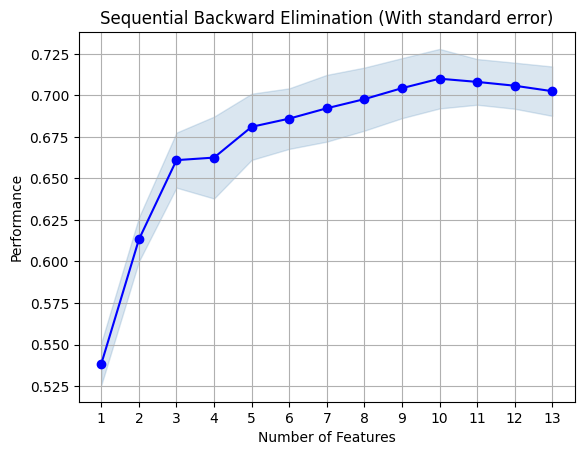

In [72]:
from mlxtend.plotting import plot_sequential_feature_selection as psfc
import matplotlib.pyplot as plt

fig = psfc(sfs.get_metric_dict(), kind = 'std_err')

plt.title('Sequential Backward Elimination (With standard error)')
plt.grid()

# The shaded area shows standard error. As cv = 5, it would train 5 models and each model
# would have its own error. So shaded area shows range of standard errors.

In [73]:
# After Sequentail Backward Selection

x_train_best = sfs.transform(x_train)
x_test_best = sfs.transform(x_test) 

print(x_train.shape)
print(x_train_best.shape)

(404, 13)
(404, 10)


In [74]:
lr = LinearRegression()

training_score = cross_val_score(
    estimator = lr,
    X = x_train_best,
    y = y_train,
    scoring = 'r2',
    cv = 5,
    verbose = True,
    n_jobs = -1
    )

testing_score = cross_val_score(
    estimator = lr,
    X = x_test_best,
    y = y_test,
    scoring = 'r2',
    cv = 5,
    verbose = 0,
    n_jobs = -1
    )


print(f"""Training R2 Score: {np.mean(training_score)}
Testing R2 Score: {np.mean(testing_score)}""")

Training R2 Score: 0.7100327839218561
Testing R2 Score: 0.7205819296124483


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done   2 out of   5 | elapsed:    0.0s remaining:    0.0s
[Parallel(n_jobs=-1)]: Done   5 out of   5 | elapsed:    0.0s finished
